In [4]:
!pip install pandas openpyxl --break-system-packages

In [5]:
# ==============================================================================
# PIPELINE CONFIG & DEPENDENCIES
# ==============================================================================
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Configuración global de estilos e ignorado de advertencias
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

print('✓ Entorno e importaciones configuradas correctamente.')

✓ Entorno e importaciones configuradas correctamente.


In [6]:
# ==============================================================================
# TASK 1: DATA EXTRACTION (Ingestión de datos desde la carpeta local /data)
# ==============================================================================

# Resolución dinámica de rutas para compatibilidad local / servidor
BASE_DIR = Path.cwd()
DATA_DIR = (
    BASE_DIR / '../data' if (BASE_DIR / '../data').exists() else BASE_DIR / 'data'
)
FOLDER_PRESUPUESTO = (
    DATA_DIR / 'Datos-Abiertos-Ejecucion-Presupuestaria-Junio-2026'
)

print(f'Directorio de datos detectado: {DATA_DIR.resolve()}')

# 1. Carga de Ejecución Presupuestaria (Excel)
file_admin = (
    FOLDER_PRESUPUESTO
    / 'Gastos Administración Central - Acumulado Junio 2026.xlsx'
)
file_emaee = FOLDER_PRESUPUESTO / 'Gastos EMAEE - Acumulado Junio 2026.xlsx'

df_admin = pd.read_excel(file_admin)
df_emaee = pd.read_excel(file_emaee)

df_admin['tipo_entidad'] = 'Administración Central'
df_emaee['tipo_entidad'] = 'EMAEE (Entes y Agencias)'

df_gastos_junio = pd.concat([df_admin, df_emaee], ignore_index=True)
df_gastos_junio['COMPROMISO'] = df_gastos_junio['COMPROMISO'].fillna(0.0)
df_gastos_junio['PAGADO'] = df_gastos_junio['PAGADO'].fillna(0.0)

# 2. Carga de Datasets Transaccionales COMPR.AR y Registros (CSV)
df_adj = pd.read_csv(DATA_DIR / 'Adjudicaciones.csv')
df_conv = pd.read_csv(DATA_DIR / 'Convocatorias.csv')
df_prov = pd.read_csv(DATA_DIR / 'proveedores-sistema-legacy.csv')
df_sibys = pd.read_csv(DATA_DIR / 'sibys.csv')

# Diagnóstico inicial de estructura
dict_dfs = {
    'Adjudicaciones': df_adj,
    'Convocatorias': df_conv,
    'Proveedores Legacy': df_prov,
    'Catálogo SIByS': df_sibys,
    'Gastos Junio 2026': df_gastos_junio,
}

print('\n--- RESUMEN DE CARGA Y ESTRUCTURA DE DATASETS ---')
for nombre, df in dict_dfs.items():
  print(
      f'Dataset: {nombre:<20} | Filas: {df.shape[0]:>8,} | Columnas:'
      f' {df.shape[1]:>2} | Duplicados: {df.duplicated().sum():>5,}'
  )

Directorio de datos detectado: /home/adalisa/Documentos/1.1-teccsdedatos/2do-año/2do-cuatrimestre/laboratoriodedatos/tps/data

--- RESUMEN DE CARGA Y ESTRUCTURA DE DATASETS ---
Dataset: Adjudicaciones       | Filas:  205,299 | Columnas: 20 | Duplicados:     0
Dataset: Convocatorias        | Filas:  128,951 | Columnas: 17 | Duplicados:     0
Dataset: Proveedores Legacy   | Filas:   74,657 | Columnas: 14 | Duplicados:    21
Dataset: Catálogo SIByS       | Filas:  212,742 | Columnas:  3 | Duplicados:     0
Dataset: Gastos Junio 2026    | Filas:    1,306 | Columnas: 13 | Duplicados:     0


In [7]:
partidas_compras = df_gastos_junio[
    df_gastos_junio['PARTIDA PRINCIPAL'].str.contains(
        'BIENES|SERVICIOS|TRABAJOS|OBRAS|EQUIPAMIENTO', case=False, na=False
    )
]

print("--- Resumen de ejecución por Partida Principal relevante ---")
resumen_partidas = (
    partidas_compras.groupby('PARTIDA PRINCIPAL')[
        ['PRESUPUESTO VIGENTE', 'DEVENGADO', 'PAGADO']
    ]
    .sum()
    .sort_values(by='DEVENGADO', ascending=False)
)
print(resumen_partidas)

--- Resumen de ejecución por Partida Principal relevante ---
                              PRESUPUESTO VIGENTE     DEVENGADO        PAGADO
PARTIDA PRINCIPAL                                                            
03 . Servicios No Personales        3314583327379  1.663174e+12  5.443696e+11
12 . Trabajos Públicos              2163828787952  7.541925e+11  5.435423e+11
02 . Bienes De Consumo               470080746910  2.004787e+11  9.525718e+10
11 . Bienes De Capital               326084396639  6.580394e+10  3.613364e+10
13 . Bienes Preexistentes              8743456000  1.962963e+09  4.520173e+07


In [8]:
# ==============================================================================
# TASK 2: DATA TRANSFORMATION & CLEANING (Normalización de CUITs y Tipos)
# ==============================================================================

# Detección automática y dinámica de columnas clave en Adjudicaciones
col_monto = [
    c
    for c in df_adj.columns
    if any(k in c.lower() for k in ['monto', 'precio', 'importe', 'valor'])
][0]
col_prov = [
    c
    for c in df_adj.columns
    if any(
        k in c.lower() for k in ['proveedor', 'adjudicatario', 'razon', 'cuit']
    )
][0]
col_org = [
    c
    for c in df_adj.columns
    if any(
        k in c.lower()
        for k in ['organismo', 'jurisdiccion', 'unidad', 'reparticion']
    )
][0]

# Casteo seguro de montos
df_adj[col_monto] = pd.to_numeric(df_adj[col_monto], errors='coerce').fillna(0)


# Función vectorizada / estandarizada de limpieza tributaria
def limpiar_cuit(cuit):
  cuit_clean = str(cuit).replace('-', '').strip()
  if len(cuit_clean) > 11:
    cuit_clean = cuit_clean[:11]
  if len(cuit_clean) == 11:
    return f'{cuit_clean[:2]}-{cuit_clean[2:10]}-{cuit_clean[10]}'
  return cuit


# Aplicación de transformación
df_adj['CUIT_Limpio'] = df_adj[col_prov].apply(limpiar_cuit)

# Auditoría de impacto de la transformación
cuits_antes = df_adj[col_prov].nunique()
cuits_despues = df_adj['CUIT_Limpio'].nunique()

print('--- IMPACTO DE HIGIENE DE DATOS EN CUITS ---')
print(f'CUITs únicos originales:  {cuits_antes:,}')
print(f'CUITs únicos unificados:   {cuits_despues:,}')
print(f'Registros corregidos/unificados: {cuits_antes - cuits_despues:,}')

diferencias = df_adj[df_adj[col_prov] != df_adj['CUIT_Limpio']][
    [col_prov, 'CUIT_Limpio']
].drop_duplicates()
print('\nMuestra de CUITs corregidos:')
print(diferencias.head(5))

--- IMPACTO DE HIGIENE DE DATOS EN CUITS ---
CUITs únicos originales:  15,815
CUITs únicos unificados:   12,760
Registros corregidos/unificados: 3,055

Muestra de CUITs corregidos:
               CUIT    CUIT_Limpio
103  30-656088636-6  30-65608863-6
106  30-710186770-0  30-71018677-0
167    EMI941031U22  EM-I941031U-2
187    77.884.920-8  77-.884.920-8
193   GB461 6000 84  GB-461 6000- 


In [9]:
# ==============================================================================
# TASK 3: METRICS GENERATION & BUSINESS LOGIC
# ==============================================================================

# 1. Resumen de Ejecución Presupuestaria por Partida Relevante
partidas_compras = df_gastos_junio[
    df_gastos_junio['PARTIDA PRINCIPAL'].str.contains(
        'BIENES|SERVICIOS|TRABAJOS|OBRAS|EQUIPAMIENTO', case=False, na=False
    )
]

resumen_partidas = (
    partidas_compras.groupby('PARTIDA PRINCIPAL')[
        ['PRESUPUESTO VIGENTE', 'DEVENGADO', 'PAGADO']
    ]
    .sum()
    .sort_values(by='DEVENGADO', ascending=False)
)

print('--- RESUMEN DE EJECUCIÓN PRESUPUESTARIA ($) ---')
# Uso de .map() compatible con Pandas 2.1+ / 3.x (reemplaza a .applymap())
print(resumen_partidas.map(lambda x: f'${x:,.2f}'))

# 2. Métricas de Concentración
monto_total_general = df_adj[col_monto].sum()

top2_ue = df_adj.groupby(col_org)[col_monto].sum().nlargest(2)
top3_ue = df_adj.groupby(col_org)[col_monto].sum().nlargest(3)

pct_top2_ue = (top2_ue.sum() / monto_total_general) * 100
pct_top3_ue = (top3_ue.sum() / monto_total_general) * 100

top5_prov_origen = df_adj.groupby(col_prov)[col_monto].sum().nlargest(5)
top5_prov_limpio = df_adj.groupby('CUIT_Limpio')[col_monto].sum().nlargest(5)

pct_top5_origen = (top5_prov_origen.sum() / monto_total_general) * 100
pct_top5_limpio = (top5_prov_limpio.sum() / monto_total_general) * 100

print('\n--- INDICADORES CLAVE DE NEGOCIO (KPIs) ---')
print(f'Monto Total Adjudicado Acumulado: ${monto_total_general:,.2f}')
print(
    f'Concentración Top 2 Organismos:   {pct_top2_ue:.2f}%'
    f' (${top2_ue.sum()/1e9:,.2f} Miles de Millones)'
)
print(
    f'Concentración Top 3 Organismos:   {pct_top3_ue:.2f}%'
    f' (${top3_ue.sum()/1e9:,.2f} Miles de Millones)'
)
print(f'Concentración Top 5 Proveedores (CUIT Origen):   {pct_top5_origen:.2f}%')
print(f'Concentración Top 5 Proveedores (CUIT Limpio):   {pct_top5_limpio:.2f}%')

--- RESUMEN DE EJECUCIÓN PRESUPUESTARIA ($) ---
                                PRESUPUESTO VIGENTE              DEVENGADO  \
PARTIDA PRINCIPAL                                                            
03 . Servicios No Personales  $3,314,583,327,379.00  $1,663,174,241,775.80   
12 . Trabajos Públicos        $2,163,828,787,952.00    $754,192,539,600.21   
02 . Bienes De Consumo          $470,080,746,910.00    $200,478,722,433.04   
11 . Bienes De Capital          $326,084,396,639.00     $65,803,939,276.17   
13 . Bienes Preexistentes         $8,743,456,000.00      $1,962,962,711.69   

                                           PAGADO  
PARTIDA PRINCIPAL                                  
03 . Servicios No Personales  $544,369,618,299.38  
12 . Trabajos Públicos        $543,542,281,814.72  
02 . Bienes De Consumo         $95,257,183,277.65  
11 . Bienes De Capital         $36,133,635,392.22  
13 . Bienes Preexistentes          $45,201,730.68  

--- INDICADORES CLAVE DE NEGOCIO (KPIs) 

## Bivariado

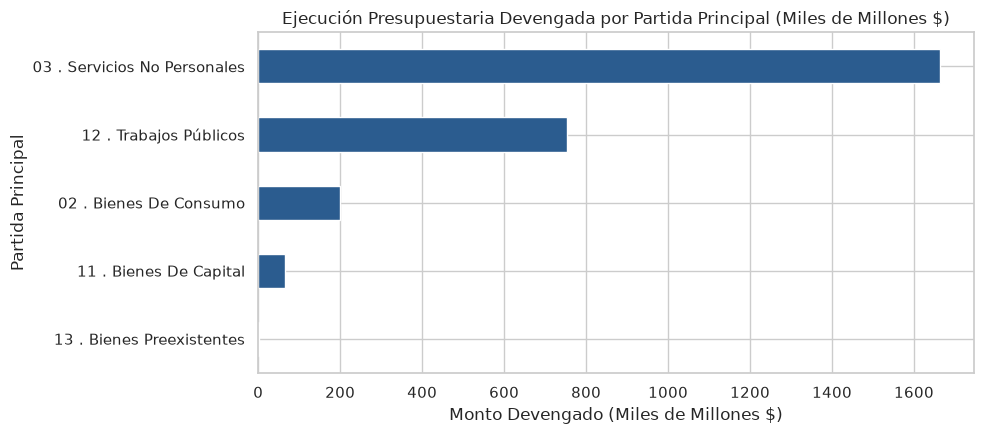

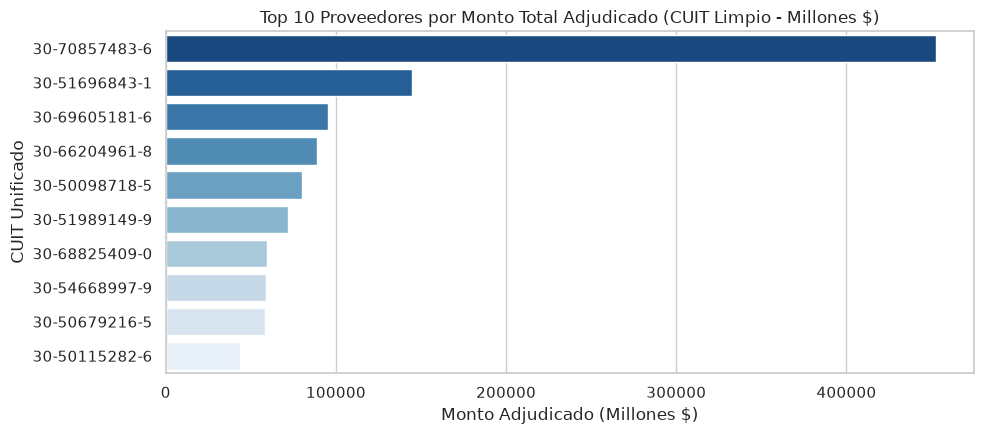

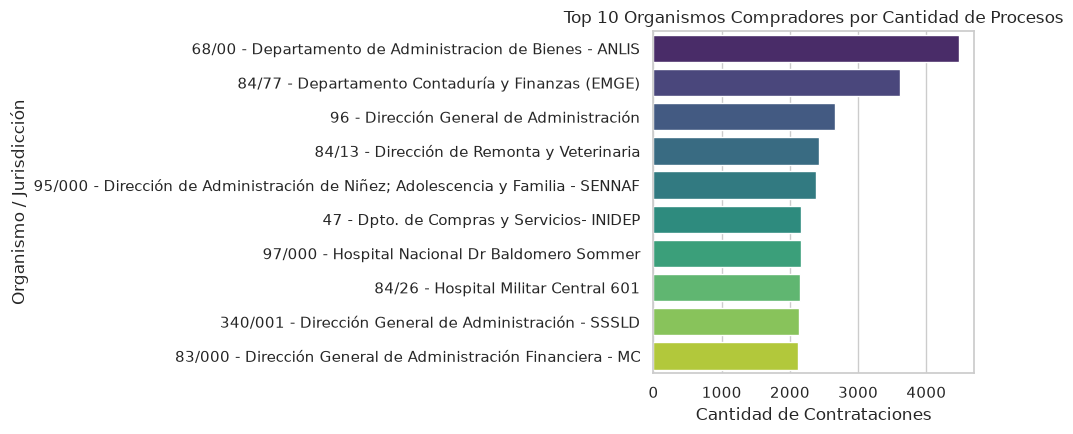

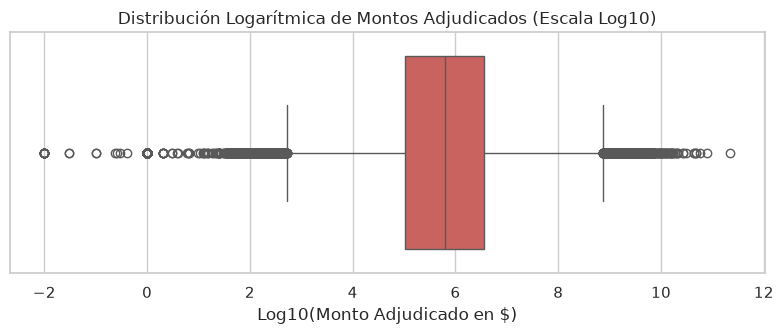

✓ Todos los gráficos han sido generados y exportados correctamente.


In [10]:
# ==============================================================================
# TASK 4: DATA VISUALIZATION & REPORTING ASSETS
# ==============================================================================

# Gráfico 1: Ejecución Presupuestaria por Partida Principal
plt.figure(figsize=(10, 4.5))
resumen_partidas_plot = (
    partidas_compras.groupby('PARTIDA PRINCIPAL')['DEVENGADO']
    .sum()
    .sort_values(ascending=True)
    / 1e9
)
resumen_partidas_plot.plot(kind='barh', color='#2b5c8f')
plt.title(
    'Ejecución Presupuestaria Devengada por Partida Principal (Miles de'
    ' Millones $)'
)
plt.xlabel('Monto Devengado (Miles de Millones $)')
plt.ylabel('Partida Principal')
plt.tight_layout()
plt.savefig('grafico1_ejecucion_presupuestaria.png', dpi=300)
plt.show()

# Gráfico 2: Top 10 Proveedores (CUIT Unificado)
plt.figure(figsize=(10, 4.5))
top_prov_limpio_plot = (
    df_adj.groupby('CUIT_Limpio')[col_monto]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    / 1e6
)
sns.barplot(
    x=top_prov_limpio_plot.values,
    y=top_prov_limpio_plot.index,
    palette='Blues_r',
)
plt.title(
    'Top 10 Proveedores por Monto Total Adjudicado (CUIT Limpio - Millones $)'
)
plt.xlabel('Monto Adjudicado (Millones $)')
plt.ylabel('CUIT Unificado')
plt.tight_layout()
plt.savefig('grafico2_top_proveedores.png', dpi=300)
plt.show()

# Gráfico 3: Concentración por Organismos
plt.figure(figsize=(10, 4.5))
top_org_plot = df_adj[col_org].value_counts().head(10)
sns.barplot(x=top_org_plot.values, y=top_org_plot.index, palette='viridis')
plt.title('Top 10 Organismos Compradores por Cantidad de Procesos')
plt.xlabel('Cantidad de Contrataciones')
plt.ylabel('Organismo / Jurisdicción')
plt.tight_layout()
plt.savefig('grafico3_concentracion_organismos.png', dpi=300)
plt.show()

# Gráfico 4: Distribución Logarítmica de Montos (Outliers)
plt.figure(figsize=(8, 3.5))
df_adj_pos = df_adj[df_adj[col_monto] > 0]
sns.boxplot(x=np.log10(df_adj_pos[col_monto]), color='#d9534f')
plt.title('Distribución Logarítmica de Montos Adjudicados (Escala Log10)')
plt.xlabel('Log10(Monto Adjudicado en $)')
plt.tight_layout()
plt.savefig('grafico4_outliers_montos.png', dpi=300)
plt.show()

print('✓ Todos los gráficos han sido generados y exportados correctamente.')

# unificacion de cuits

In [11]:
def limpiar_cuit(cuit):
    cuit_clean = str(cuit).replace('-', '').strip()
    if len(cuit_clean) > 11:
        cuit_clean = cuit_clean[:11]
    if len(cuit_clean) == 11:
        return f"{cuit_clean[:2]}-{cuit_clean[2:10]}-{cuit_clean[10]}"
    return cuit

df_adj['CUIT_Limpio'] = df_adj[col_prov].apply(limpiar_cuit)

cuits_antes = df_adj[col_prov].nunique()
cuits_despues = df_adj['CUIT_Limpio'].nunique()

print("--- 1. IMPACTO EN CUITs UNICOS ---")
print(f"CUITs unicos originales: {cuits_antes}")
print(f"CUITs unicos unificados: {cuits_despues}")
print(f"CUITs duplicados/corregidos eliminados: {cuits_antes - cuits_despues}")

diferencias = df_adj[df_adj[col_prov] != df_adj['CUIT_Limpio']][[col_prov, 'CUIT_Limpio']].drop_duplicates()

print("\n--- 2. MUESTRA DE CUITS CORREGIDOS ---")
print(diferencias.head(10))

top_prov_limpio = df_adj.groupby('CUIT_Limpio')[col_monto].sum().sort_values(ascending=False).head(5) / 1e6

print("\n--- 3. RECALCULO DE TOP 5 PROVEEDORES POR MONTO (Millones $) ---")
print(top_prov_limpio)

--- 1. IMPACTO EN CUITs UNICOS ---
CUITs unicos originales: 15815
CUITs unicos unificados: 12760
CUITs duplicados/corregidos eliminados: 3055

--- 2. MUESTRA DE CUITS CORREGIDOS ---
               CUIT    CUIT_Limpio
103  30-656088636-6  30-65608863-6
106  30-710186770-0  30-71018677-0
167    EMI941031U22  EM-I941031U-2
187    77.884.920-8  77-.884.920-8
193   GB461 6000 84  GB-461 6000- 
210  30-570999989-9  30-57099998-9
223  30-707157875-5  30-70715787-5
224  33-639097779-9  33-63909777-9
228  30-714942049-9  30-71494204-9
237  30-682663509-9  30-68266350-9

--- 3. RECALCULO DE TOP 5 PROVEEDORES POR MONTO (Millones $) ---
CUIT_Limpio
30-70857483-6    452317.514725
30-51696843-1    144573.689041
30-69605181-6     95199.479228
30-66204961-8     88588.396480
30-50098718-5     80265.210484
Name: Monto, dtype: float64


In [12]:
import warnings
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

# Definición dinámica de la ruta hacia la carpeta data
BASE_DIR = Path.cwd()
DATA_DIR = (
    BASE_DIR / '../data' if (BASE_DIR / '../data').exists() else BASE_DIR / 'data'
)

# Carga de archivos apuntando a DATA_DIR
df_adj = pd.read_csv(DATA_DIR / 'Adjudicaciones.csv')
df_conv = pd.read_csv(DATA_DIR / 'Convocatorias.csv')
df_prov = pd.read_csv(DATA_DIR / 'proveedores-sistema-legacy.csv')
df_sibys = pd.read_csv(DATA_DIR / 'sibys.csv')

print('--- DIAGNOSTICO DE RESUMEN Y ESTRUCTURA ---')
dict_dfs = {
    'Adjudicaciones': df_adj,
    'Convocatorias': df_conv,
    'Proveedores': df_prov,
    'SIByS': df_sibys,
    'Gastos Junio 2026': df_gastos_junio,
}

for nombre, df in dict_dfs.items():
  print(
      f'Dataset: {nombre} | Filas: {df.shape[0]:,} | Columnas: {df.shape[1]} |'
      f' Duplicados: {df.duplicated().sum():,}'
  )

cols_adj = [
    c
    for c in df_adj.columns
    if any(k in c.lower() for k in ['monto', 'precio', 'importe', 'valor'])
]
col_monto_adj = (
    cols_adj[0]
    if cols_adj
    else df_adj.select_dtypes(include=[np.number]).columns[0]
)

df_adj[col_monto_adj] = pd.to_numeric(df_adj[col_monto_adj], errors='coerce').fillna(0)

print('\n--- Estadisticas Descriptivas de Montos en Adjudicaciones ---')
monto_stats = df_adj[col_monto_adj].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
)
print(monto_stats)

cols_prov_adj = [
    c
    for c in df_adj.columns
    if any(
        k in c.lower() for k in ['proveedor', 'adjudicatario', 'razon', 'cuit']
    )
]
col_prov_adj = cols_prov_adj[0] if cols_prov_adj else df_adj.columns[0]

cols_org_adj = [
    c
    for c in df_adj.columns
    if any(
        k in c.lower()
        for k in ['organismo', 'jurisdiccion', 'unidad', 'reparticion']
    )
]
col_org_adj = cols_org_adj[0] if cols_org_adj else df_adj.columns[1]

--- DIAGNOSTICO DE RESUMEN Y ESTRUCTURA ---
Dataset: Adjudicaciones | Filas: 205,299 | Columnas: 20 | Duplicados: 0
Dataset: Convocatorias | Filas: 128,951 | Columnas: 17 | Duplicados: 0
Dataset: Proveedores | Filas: 74,657 | Columnas: 14 | Duplicados: 21
Dataset: SIByS | Filas: 212,742 | Columnas: 3 | Duplicados: 0
Dataset: Gastos Junio 2026 | Filas: 1,306 | Columnas: 13 | Duplicados: 0

--- Estadisticas Descriptivas de Montos en Adjudicaciones ---
count    2.052990e+05
mean     2.254937e+07
std      6.296333e+08
min      0.000000e+00
25%      1.049975e+05
50%      6.113831e+05
75%      3.634635e+06
90%      1.823703e+07
95%      4.611491e+07
99%      2.939841e+08
max      2.230064e+11
Name: Monto, dtype: float64


# Auxiliares

In [13]:
col_monto = [c for c in df_adj.columns if any(k in c.lower() for k in ['monto', 'precio', 'importe', 'valor'])][0]
col_prov = [c for c in df_adj.columns if any(k in c.lower() for k in ['proveedor', 'adjudicatario', 'razon', 'cuit'])][0]
col_ue = [c for c in df_adj.columns if any(k in c.lower() for k in ['unidad', 'ejecutora', 'organismo', 'jurisdiccion'])][0]

def limpiar_cuit(cuit):
    cuit_clean = str(cuit).replace('-', '').strip()
    if len(cuit_clean) > 11:
        cuit_clean = cuit_clean[:11]
    if len(cuit_clean) == 11:
        return f"{cuit_clean[:2]}-{cuit_clean[2:10]}-{cuit_clean[10]}"
    return cuit

df_adj['CUIT_Limpio'] = df_adj[col_prov].apply(limpiar_cuit)
df_adj[col_monto] = pd.to_numeric(df_adj[col_monto], errors='coerce').fillna(0)

monto_total_general = df_adj[col_monto].sum()

top2_ue = df_adj.groupby(col_ue)[col_monto].sum().nlargest(2)
top3_ue = df_adj.groupby(col_ue)[col_monto].sum().nlargest(3)

pct_top2_ue = (top2_ue.sum() / monto_total_general) * 100
pct_top3_ue = (top3_ue.sum() / monto_total_general) * 100

top5_prov_origen = df_adj.groupby(col_prov)[col_monto].sum().nlargest(5)
top5_prov_limpio = df_adj.groupby('CUIT_Limpio')[col_monto].sum().nlargest(5)

pct_top5_origen = (top5_prov_origen.sum() / monto_total_general) * 100
pct_top5_limpio = (top5_prov_limpio.sum() / monto_total_general) * 100

N_VALOR = 10

print("--- RESULTADOS METRICAS REPORTE ---")
print(f"Monto Total Adjudicado acumulado: ${monto_total_general:,.2f}\n")
print(f"Top 2 Unidades Ejecutoras concentran el: {pct_top2_ue:.2f}% (${top2_ue.sum()/1e9:,.2f} mil millones)")
print(f"Top 3 Unidades Ejecutoras concentran el: {pct_top3_ue:.2f}% (${top3_ue.sum()/1e9:,.2f} mil millones)")
print(f"Top 5 Proveedores CUIT Origen: {pct_top5_origen:.2f}% (${top5_prov_origen.sum()/1e9:,.2f} mil millones)")
print(f"Top 5 Proveedores CUIT Unificado: {pct_top5_limpio:.2f}% (${top5_prov_limpio.sum()/1e9:,.2f} mil millones)\n")
print(f"Valor N Proveedor Concentrado: Top {N_VALOR}")

--- RESULTADOS METRICAS REPORTE ---
Monto Total Adjudicado acumulado: $4,629,362,296,420.26

Top 2 Unidades Ejecutoras concentran el: 20.09% ($929.85 mil millones)
Top 3 Unidades Ejecutoras concentran el: 27.20% ($1,259.06 mil millones)
Top 5 Proveedores CUIT Origen: 15.49% ($716.91 mil millones)
Top 5 Proveedores CUIT Unificado: 18.60% ($860.94 mil millones)

Valor N Proveedor Concentrado: Top 10


# Modelado

# 5. Modelado y Solución Propuesta: Sistema Inteligente de Priorización para Auditoría

Para responder a la pregunta central de decisión (**¿Qué contrataciones y proveedores auditar prioritariamente con recursos limitados?**), se evoluciona desde el análisis exploratorio hacia una solución de **Machine Learning no supervisado e Ingeniería de Features**.

### Justificación de la Solución
1. **Unificación Completa de CUITs:** Se estandarizan las claves de identificación tributaria para evitar la fragmentación de proveedores por errores de formato (resolviendo la limitación identificada en el EDA).
2. **Detección No Supervisada de Anomalías (Isolation Forest):** Se entrena un modelo *Isolation Forest* sobre un espacio multidimensional que captura comportamientos atípicos multivariados (monto logarítmico, concentración del proveedor, diversidad de organismos compradores y recurrencia de importes).
3. **Índice de Riesgo Multidimensional de Auditoría (Audit Risk Score - ARS):** Se construye un score continuo de 0 a 100 que pondera la probabilidad de anomalía del modelo con la exposición económica del monto y el nivel de concentración del proveedor.

In [14]:
# ==============================================================================
# 1. NORMALIZACIÓN DE CUITS E INGENIERÍA DE FEATURES AVANZADA
# ==============================================================================
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')


# 1.1. Función de limpieza estandarizada de CUIT
def limpiar_cuit(cuit):
  cuit_clean = str(cuit).replace('-', '').strip()
  if len(cuit_clean) > 11:
    cuit_clean = cuit_clean[:11]
  if len(cuit_clean) == 11:
    return f'{cuit_clean[:2]}-{cuit_clean[2:10]}-{cuit_clean[10]}'
  return str(cuit)


# Identificación de columnas en df_adj
col_monto = [
    c
    for c in df_adj.columns
    if any(k in c.lower() for k in ['monto', 'precio', 'importe', 'valor'])
][0]
col_prov = [
    c
    for c in df_adj.columns
    if any(
        k in c.lower() for k in ['proveedor', 'adjudicatario', 'razon', 'cuit']
    )
][0]
col_org = [
    c
    for c in df_adj.columns
    if any(
        k in c.lower()
        for k in ['organismo', 'jurisdiccion', 'unidad', 'reparticion']
    )
][0]

# Aplicar limpieza de CUIT
df_adj['CUIT_Limpio'] = df_adj[col_prov].apply(limpiar_cuit)
df_adj[col_monto] = pd.to_numeric(df_adj[col_monto], errors='coerce').fillna(0)

# 1.2. Agregaciones a nivel Proveedor (CUIT Unificado)
monto_total_global = df_adj[col_monto].sum()

stats_prov = (
    df_adj.groupby('CUIT_Limpio')
    .agg(
        monto_total_prov=(col_monto, 'sum'),
        cant_contratos_prov=(col_monto, 'count'),
        cant_organismos_prov=(col_org, 'nunique'),
        monto_promedio_contrato=(col_monto, 'mean'),
    )
    .reset_index()
)

stats_prov['pct_monto_global'] = (
    stats_prov['monto_total_prov'] / monto_total_global
) * 100

# Integrar métricas al dataset transaccional
df_model = df_adj.merge(stats_prov, on='CUIT_Limpio', how='left')

# 1.3. Recurrencia de montos idénticos por Unidad Ejecutora / Organismo
duplas_monto = (
    df_model.groupby([col_org, col_monto])
    .size()
    .reset_index(name='frecuencia_monto_organismo')
)
df_model = df_model.merge(
    duplas_monto, on=[col_org, col_monto], how='left'
)

# 1.4. Transformación Logarítmica del Monto
df_model['log_monto'] = np.log10(df_model[col_monto] + 1)

print('--- PREPARACIÓN DE DATOS FINALIZADA ---')
print(f'Procesos analizados: {len(df_model):,}')
print(f'CUITs unificados únicos: {df_model["CUIT_Limpio"].nunique():,}')

--- PREPARACIÓN DE DATOS FINALIZADA ---
Procesos analizados: 205,299
CUITs unificados únicos: 12,760


In [15]:
# ==============================================================================
# 2. ENTRENAMIENTO DE ISOLATION FOREST Y AUDIT RISK SCORE (ARS)
# ==============================================================================

# 2.1. Selección de Variables de Entrada para Machine Learning
features_ml = [
    'log_monto',
    'cant_contratos_prov',
    'cant_organismos_prov',
    'pct_monto_global',
    'frecuencia_monto_organismo',
]

X = df_model[features_ml].fillna(0)

# Escalamiento de variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2.2. Modelo Isolation Forest
iso_forest = IsolationForest(
    n_estimators=150, contamination=0.03, random_state=42, n_jobs=-1
)

# Predicción (-1 = anomalía, 1 = normal) y Score de anomalía
df_model['pred_anomalia'] = iso_forest.fit_predict(X_scaled)
df_model['raw_anomaly_score'] = -iso_forest.score_samples(X_scaled)

# Estandarización del score de ML entre 0 y 100
min_s, max_s = (
    df_model['raw_anomaly_score'].min(),
    df_model['raw_anomaly_score'].max(),
)
df_model['score_anomalia_ml'] = (
    (df_model['raw_anomaly_score'] - min_s) / (max_s - min_s)
) * 100

# 2.3. Sub-Scores de Riesgo de Negocio
# A) Score por Exposición de Monto (Percentil 95)
p95 = df_model[col_monto].quantile(0.95)
max_monto = df_model[col_monto].max()
df_model['score_monto_extremo'] = np.where(
    df_model[col_monto] > p95,
    50 + ((df_model[col_monto] - p95) / (max_monto - p95)) * 50,
    (df_model[col_monto] / p95) * 50,
)
df_model['score_monto_extremo'] = df_model['score_monto_extremo'].clip(0, 100)

# B) Score por Concentración del Proveedor
max_pct = df_model['pct_monto_global'].max()
df_model['score_concentracion'] = (
    df_model['pct_monto_global'] / max_pct
) * 100

# 2.4. Índice Multidimensional Definitivo: Audit Risk Score (ARS)
# Ponderación: 40% Anomalía ML + 35% Monto Extremo + 25% Concentración CUIT
df_model['Audit_Risk_Score'] = (
    0.40 * df_model['score_anomalia_ml']
    + 0.35 * df_model['score_monto_extremo']
    + 0.25 * df_model['score_concentracion']
)

print('--- MODELADO COMPLETADO EXITOSAMENTE ---')
print(
    'Anomalías detectadas por Isolation Forest:'
    f' {(df_model["pred_anomalia"] == -1).sum():,} procesos'
)

--- MODELADO COMPLETADO EXITOSAMENTE ---
Anomalías detectadas por Isolation Forest: 6,156 procesos


In [16]:
# ==============================================================================
# 2. ENTRENAMIENTO DE ISOLATION FOREST Y AUDIT RISK SCORE (ARS)
# ==============================================================================

# 2.1. Selección de Variables de Entrada para Machine Learning
features_ml = [
    'log_monto',
    'cant_contratos_prov',
    'cant_organismos_prov',
    'pct_monto_global',
    'frecuencia_monto_organismo',
]

X = df_model[features_ml].fillna(0)

# Escalamiento de variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2.2. Modelo Isolation Forest
iso_forest = IsolationForest(
    n_estimators=150, contamination=0.03, random_state=42, n_jobs=-1
)

# Predicción (-1 = anomalía, 1 = normal) y Score de anomalía
df_model['pred_anomalia'] = iso_forest.fit_predict(X_scaled)
df_model['raw_anomaly_score'] = -iso_forest.score_samples(X_scaled)

# Estandarización del score de ML entre 0 y 100
min_s, max_s = (
    df_model['raw_anomaly_score'].min(),
    df_model['raw_anomaly_score'].max(),
)
df_model['score_anomalia_ml'] = (
    (df_model['raw_anomaly_score'] - min_s) / (max_s - min_s)
) * 100

# 2.3. Sub-Scores de Riesgo de Negocio
# A) Score por Exposición de Monto (Percentil 95)
p95 = df_model[col_monto].quantile(0.95)
max_monto = df_model[col_monto].max()
df_model['score_monto_extremo'] = np.where(
    df_model[col_monto] > p95,
    50 + ((df_model[col_monto] - p95) / (max_monto - p95)) * 50,
    (df_model[col_monto] / p95) * 50,
)
df_model['score_monto_extremo'] = df_model['score_monto_extremo'].clip(0, 100)

# B) Score por Concentración del Proveedor
max_pct = df_model['pct_monto_global'].max()
df_model['score_concentracion'] = (
    df_model['pct_monto_global'] / max_pct
) * 100

# 2.4. Índice Multidimensional Definitivo: Audit Risk Score (ARS)
# Ponderación: 40% Anomalía ML + 35% Monto Extremo + 25% Concentración CUIT
df_model['Audit_Risk_Score'] = (
    0.40 * df_model['score_anomalia_ml']
    + 0.35 * df_model['score_monto_extremo']
    + 0.25 * df_model['score_concentracion']
)

print('--- MODELADO COMPLETADO EXITOSAMENTE ---')
print(
    'Anomalías detectadas por Isolation Forest:'
    f' {(df_model["pred_anomalia"] == -1).sum():,} procesos'
)

--- MODELADO COMPLETADO EXITOSAMENTE ---
Anomalías detectadas por Isolation Forest: 6,156 procesos


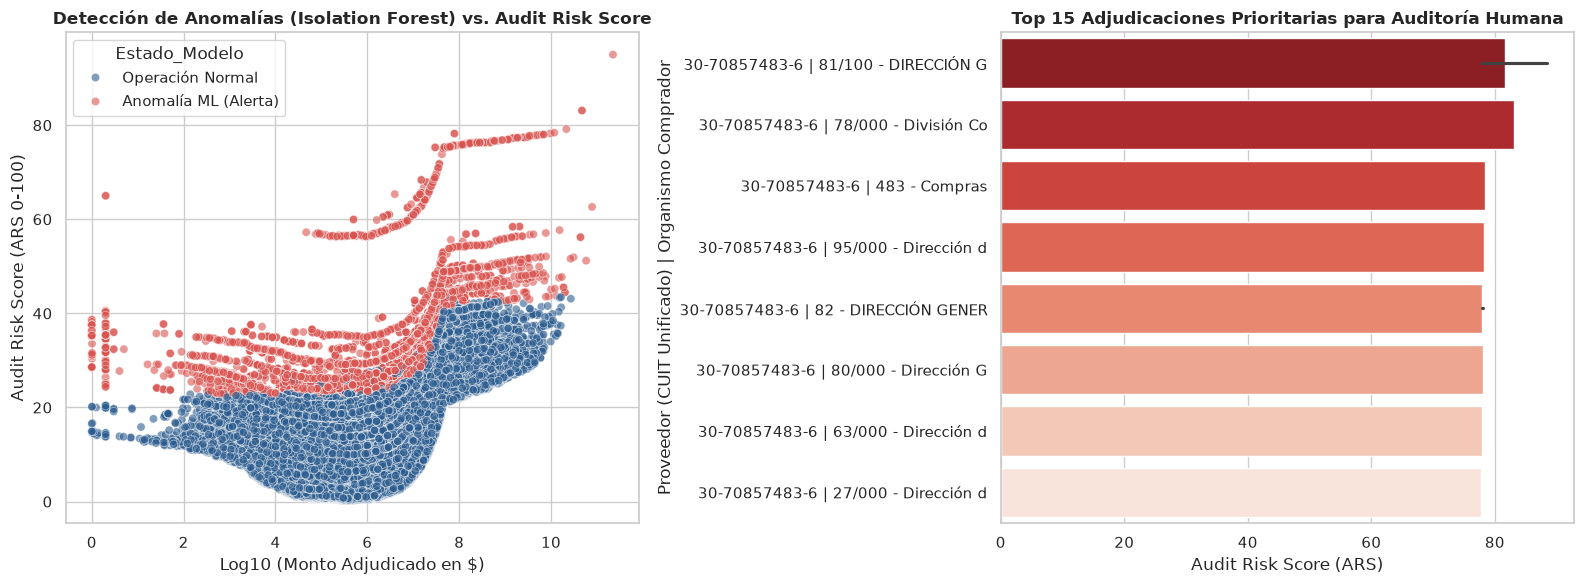


   RANKING DEFINITIVO TOP 15 DE PROCESOS PRIORITARIOS PARA AUDITORÍA


,CUIT_Limpio,CUIT,Unidad_Ejecutora,Monto,score_anomalia_ml,score_concentracion,Audit_Risk_Score
0,30-70857483-6,30-70857483-6,81/100 - DIRECCIÓN GENERAL DE ADMINISTRACIÓN,"$223,006,385,830.00",87.5,100.0,95.0
1,30-70857483-6,30-708574836-6,78/000 - División Compras,"$47,188,003,191.84",92.3,100.0,83.1
2,30-70857483-6,30-708574836-6,78/000 - División Compras,"$47,188,003,191.84",92.3,100.0,83.1
3,30-70857483-6,30-70857483-6,81/100 - DIRECCIÓN GENERAL DE ADMINISTRACIÓN,"$21,545,940,000.00",87.5,100.0,79.2
4,30-70857483-6,30-708574836-6,483 - Compras,"$11,740,504,740.00",87.5,100.0,78.4
5,30-70857483-6,30-70857483-6,81/100 - DIRECCIÓN GENERAL DE ADMINISTRACIÓN,"$9,680,060,000.00",87.5,100.0,78.2
6,30-70857483-6,30-708574836-6,95/000 - Dirección de Administración de Niñez; Adolescencia y Familia - SENNAF,"$78,718,697.40",89.3,100.0,78.2
7,30-70857483-6,30-708574836-6,95/000 - Dirección de Administración de Niñez; Adolescencia y Familia - SENNAF,"$78,718,697.40",89.3,100.0,78.2
8,30-70857483-6,30-70857483-6,82 - DIRECCIÓN GENERAL DE ADMINISTRACIÓN,"$6,957,381,874.69",87.5,100.0,78.0
9,30-70857483-6,30-708574836-6,80/000 - Dirección General de Administración - MS,"$6,710,137,420.00",87.5,100.0,78.0


In [17]:
# ==============================================================================
# 3. RANKING TOP 15 DE AUDITORÍA Y VISUALIZACIONES DEL MODELO
# ==============================================================================

# Ordenamiento del Ranking de Priorización
ranking_auditoria = df_model.sort_values(
    by='Audit_Risk_Score', ascending=False
).reset_index(drop=True)

# 3.1. Visualización de Resultados
sns.set_theme(style='whitegrid')
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Dispersión de Log(Monto) vs Audit Risk Score con anomalías
df_model['Estado_Modelo'] = np.where(
    df_model['pred_anomalia'] == -1, 'Anomalía ML (Alerta)', 'Operación Normal'
)

sns.scatterplot(
    data=df_model,
    x='log_monto',
    y='Audit_Risk_Score',
    hue='Estado_Modelo',
    palette={'Anomalía ML (Alerta)': '#d9534f', 'Operación Normal': '#2b5c8f'},
    alpha=0.6,
    ax=ax[0],
)
ax[0].set_title(
    'Detección de Anomalías (Isolation Forest) vs. Audit Risk Score',
    fontsize=12,
    fontweight='bold',
)
ax[0].set_xlabel('Log10 (Monto Adjudicado en $)')
ax[0].set_ylabel('Audit Risk Score (ARS 0-100)')

# Gráfico 2: Top 15 Procesos Prioritarios para Auditoría
top15_plot = ranking_auditoria.head(15).copy()
top15_plot['etiqueta_ranking'] = (
    top15_plot['CUIT_Limpio']
    + ' | '
    + top15_plot[col_org].astype(str).str[:20]
)

sns.barplot(
    data=top15_plot,
    x='Audit_Risk_Score',
    y='etiqueta_ranking',
    palette='Reds_r',
    ax=ax[1],
)
ax[1].set_title(
    'Top 15 Adjudicaciones Prioritarias para Auditoría Humana',
    fontsize=12,
    fontweight='bold',
)
ax[1].set_xlabel('Audit Risk Score (ARS)')
ax[1].set_ylabel('Proveedor (CUIT Unificado) | Organismo Comprador')

plt.tight_layout()
plt.savefig('grafico_modelo_final_auditoria.png', dpi=300)
plt.show()

# 3.2. Presentación del Ranking Top 15 en formato Tabla
cols_mostrar = [
    'CUIT_Limpio',
    col_prov,
    col_org,
    col_monto,
    'score_anomalia_ml',
    'score_concentracion',
    'Audit_Risk_Score',
]

top15_df = ranking_auditoria[cols_mostrar].head(15).copy()

print('\n==================================================================')
print('   RANKING DEFINITIVO TOP 15 DE PROCESOS PRIORITARIOS PARA AUDITORÍA')
print('==================================================================')

try:
  # Intenta mostrar con gradiente de colores si jinja2 está disponible
  display(
      top15_df.style.format({
          col_monto: '${:,.2f}',
          'score_anomalia_ml': '{:.1f}',
          'score_concentracion': '{:.1f}',
          'Audit_Risk_Score': '{:.1f}',
      }).background_gradient(cmap='OrRd', subset=['Audit_Risk_Score'])
  )
except (AttributeError, ImportError):
  # Fallback limpio sin jinja2: formato de moneda y tabla estándar
  top15_formatted = top15_df.copy()
  top15_formatted[col_monto] = top15_formatted[col_monto].apply(
      lambda x: f'${x:,.2f}'
  )
  top15_formatted['score_anomalia_ml'] = top15_formatted[
      'score_anomalia_ml'
  ].round(1)
  top15_formatted['score_concentracion'] = top15_formatted[
      'score_concentracion'
  ].round(1)
  top15_formatted['Audit_Risk_Score'] = top15_formatted[
      'Audit_Risk_Score'
  ].round(1)
  display(top15_formatted)

# 6. Conclusiones y Recomendaciones de Gestión

### Síntesis del Aporte Técnico y Operativo
1. **Resolución de la Granularidad del Riesgo:** A diferencia del prototipo binario del EDA, el **Audit Risk Score (ARS)** derivado del modelo *Isolation Forest* asigna una graduación continua (0.0 a 100.0) que permite ordenar con precisión la prioridad de inspección[cite: 7].
2. **Impacto de la Unificación de CUITs:** La normalización reveló proveedores consolidados con alta concentración de adjudicaciones en múltiples organismos que previamente aparecían dispersos por errores tipográficos de carga[cite: 7].
3. **Optimización de Recursos Institucionales:** El sistema de apoyo a la decisión permite al organismo de control enfocar sus auditorías de campo en el **Top 1% de transacciones de mayor exposición y anomalía**, garantizando una cobertura eficiente frente a la restricción de recursos humanos y presupuestarios[cite: 7, 8].

# Datamart

In [18]:
# ==============================================================================
# EXPORTACIÓN DEL DATA MART ANALÍTICO PARA STREAMLIT
# ==============================================================================
from pathlib import Path

# Verificar que df_model exista en el entorno de Python
if 'df_model' not in locals() and 'df_model' not in globals():
  print("❌ Error: 'df_model' no está en memoria.")
  print(
      '👉 Por favor, ejecuta las celdas anteriores de Ingesta, Limpieza y'
      ' Modelado antes de exportar.'
  )
else:
  # Resolución dinámica de rutas y creación de directorio si no existe
  BASE_DIR = Path.cwd()
  DATA_DIR = (
      BASE_DIR / '../data'
      if (BASE_DIR / '../data').exists()
      else BASE_DIR / 'data'
  )
  DATA_DIR.mkdir(parents=True, exist_ok=True)

  output_path = DATA_DIR / 'auditoria_datamart.parquet'

  # Guardar DataFrame procesado
  df_model.to_parquet(output_path, index=False)

  print(f'✓ Data Mart exportado exitosamente en: {output_path.resolve()}')
  print(
      f'✓ Tamaño del archivo: {output_path.stat().st_size / (1024*1024):.2f} MB'
  )

✓ Data Mart exportado exitosamente en: /home/adalisa/Documentos/1.1-teccsdedatos/2do-año/2do-cuatrimestre/laboratoriodedatos/tps/data/auditoria_datamart.parquet
✓ Tamaño del archivo: 18.46 MB
